# Oliver_Austin_HW5

Name: Austin Oliver  
GitHub username: awoliver335  
USC ID:

DSCI 552 - Homework 5

Both datasets are in the `data` folder. I used a random seed of 552 so the
cross-validation results can be reproduced.

### Install packages

Run this cell if any of the packages are missing. Restart the kernel if prompted.

In [1]:
### %pip install numpy pandas matplotlib seaborn scikit-learn xgboost ipython threadpoolctl

## 1. Decision Trees as Interpretable Models

### Import packages

In [2]:
from pathlib import Path
from textwrap import fill

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from threadpoolctl import threadpool_limits
from xgboost import XGBRegressor

SEED = 552
DATA_DIR = Path("data")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})

### (a) Obtain data

The Acute Inflammations dataset has 120 observations, six predictors, and two
diagnosis labels. I encoded yes/no as 1/0 and used label powerset to combine the
diagnoses into four classes: neither disease, nephritis only, bladder inflammation
only, and both. This lets one tree predict the two diagnoses together.

In [3]:
diagnosis_columns = [
    "temperature", "nausea", "lumbar_pain", "urine_pushing",
    "micturition_pain", "urethra_burning", "bladder_inflammation", "nephritis",
]
# The file uses UTF-16 and decimal commas.
diagnosis = pd.read_csv(
    DATA_DIR / "diagnosis.data", sep="\t", decimal=",", encoding="utf-16",
    header=None, names=diagnosis_columns,
)
for column in diagnosis_columns[1:]:
    diagnosis[column] = diagnosis[column].map({"no": 0, "yes": 1})

X_diagnosis = diagnosis.iloc[:, :6].copy()
Y_diagnosis = diagnosis[["bladder_inflammation", "nephritis"]].copy()
# Joint classes: 0 = neither, 1 = nephritis, 2 = bladder, 3 = both.
y_joint = 2 * Y_diagnosis["bladder_inflammation"] + Y_diagnosis["nephritis"]
diagnosis_labels = {
    0: "Neither", 1: "Nephritis only", 2: "Bladder only", 3: "Both",
}
diagnosis_outcomes = {
    0: "bladder inflammation = no; nephritis = no",
    1: "bladder inflammation = no; nephritis = yes",
    2: "bladder inflammation = yes; nephritis = no",
    3: "bladder inflammation = yes; nephritis = yes",
}
class_counts = y_joint.value_counts().sort_index().rename("observations").to_frame()
class_counts.insert(0, "diagnosis", [diagnosis_labels[i] for i in class_counts.index])
display(class_counts)

,diagnosis,observations
0,Neither,30
1,Nephritis only,31
2,Bladder only,40
3,Both,19


### (b) Build a decision tree

I fitted a decision tree with Gini impurity to all 120 observations, as requested.
The reported accuracy is training accuracy since the same data are used for fitting
and evaluation here.

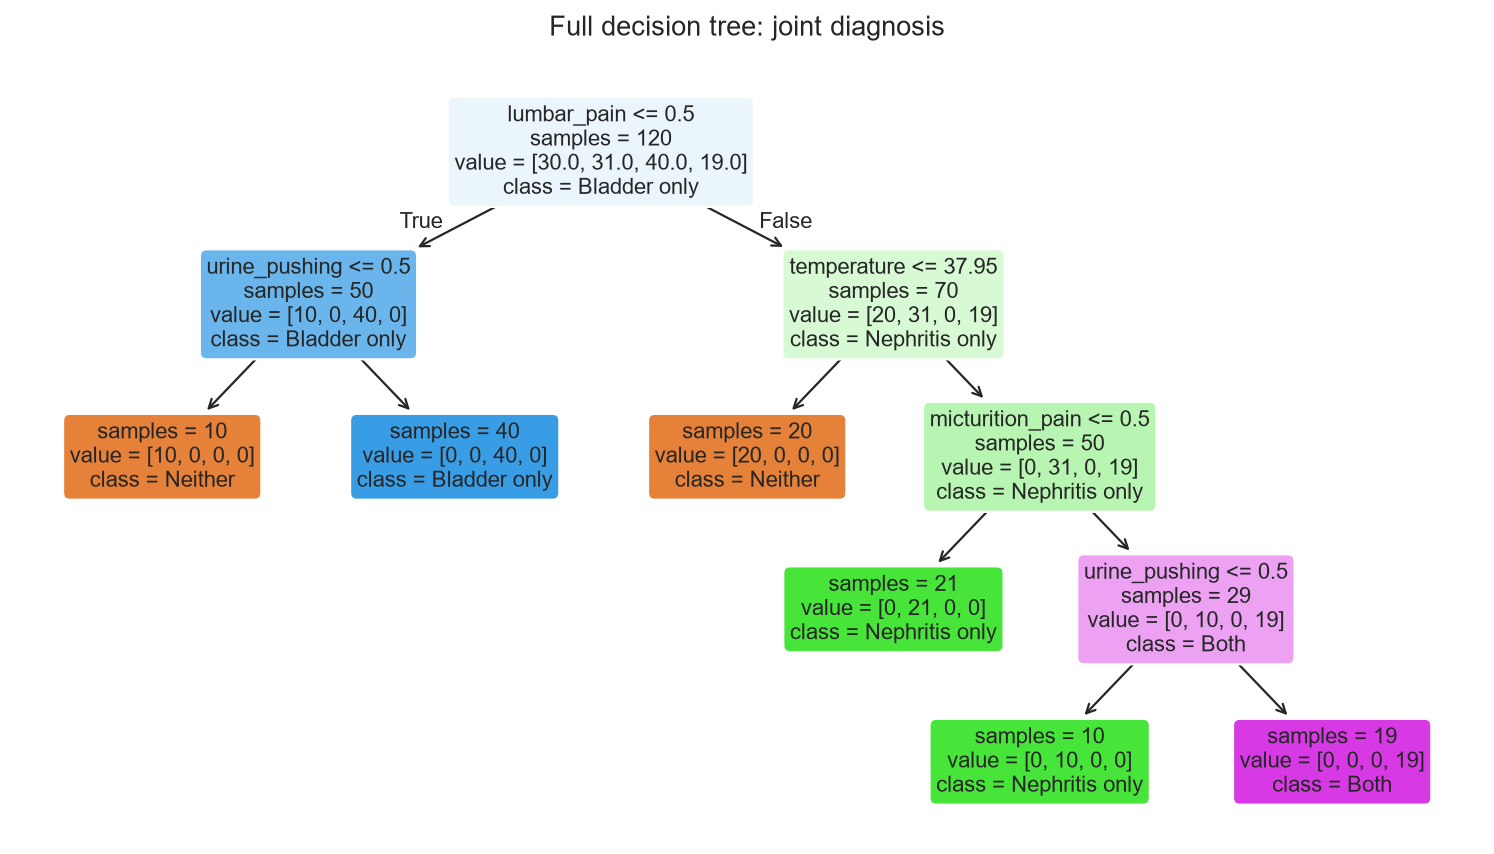

Depth: 4, leaves: 6
Joint training accuracy: 100.000%


In [4]:
full_tree = DecisionTreeClassifier(random_state=SEED)
full_tree.fit(X_diagnosis, y_joint)

def show_diagnosis_tree(model, title):
    height = 5.5 if model.get_depth() > 2 else 3.8
    fig, ax = plt.subplots(figsize=(9.5, height), dpi=160)
    plot_tree(
        model, feature_names=X_diagnosis.columns.tolist(),
        class_names=[diagnosis_labels[int(c)] for c in model.classes_],
        filled=True, rounded=True, impurity=False, precision=2,
        fontsize=10, ax=ax,
    )
    ax.set_title(title, pad=18)
    fig.tight_layout()
    plt.show()

show_diagnosis_tree(full_tree, "Full decision tree: joint diagnosis")
print(f"Depth: {full_tree.get_depth()}, leaves: {full_tree.get_n_leaves()}")
print(f"Joint training accuracy: {full_tree.score(X_diagnosis, y_joint):.3%}")

The tree has six leaves and depth four, and it correctly classifies all 120
training observations. This shows that the tree fits this dataset exactly,
but the training accuracy alone does not tell us how it would perform on new data.

### (c) IF-THEN rules

Each path from the root to a leaf gives one rule. For the binary symptoms, a split
at 0.5 is equivalent to checking whether the symptom is absent or present.

In [5]:
def extract_rules(model):
    tree = model.tree_
    rules = []

    def visit(node, conditions):
        left, right = tree.children_left[node], tree.children_right[node]
        if left == right:  # leaf
            class_index = int(np.argmax(tree.value[node][0]))
            predicted_class = int(model.classes_[class_index])
            leaf_values = tree.value[node][0]
            purity = float(leaf_values[class_index] / leaf_values.sum())
            rules.append({
                "IF": " AND ".join(conditions) if conditions else "always",
                "THEN": diagnosis_outcomes[predicted_class],
                "samples": int(tree.n_node_samples[node]),
                "leaf purity": purity,
            })
            return
        feature = X_diagnosis.columns[tree.feature[node]]
        threshold = tree.threshold[node]
        if feature == "temperature":
            left_rule = f"temperature <= {threshold:.2f} C"
            right_rule = f"temperature > {threshold:.2f} C"
        else:
            left_rule = f"{feature} = no"
            right_rule = f"{feature} = yes"
        visit(left, conditions + [left_rule])
        visit(right, conditions + [right_rule])

    visit(0, [])
    return pd.DataFrame(rules)

def print_rules(model):
    rules = extract_rules(model)
    for i, row in rules.iterrows():
        print(f"Rule {i + 1}: IF {row['IF']}")
        print(f"  THEN {row['THEN']} "
              f"(n={row['samples']}, purity={row['leaf purity']:.1%}).")
    return rules

full_rules = print_rules(full_tree)

Rule 1: IF lumbar_pain = no AND urine_pushing = no
  THEN bladder inflammation = no; nephritis = no (n=10, purity=100.0%).
Rule 2: IF lumbar_pain = no AND urine_pushing = yes
  THEN bladder inflammation = yes; nephritis = no (n=40, purity=100.0%).
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 C
  THEN bladder inflammation = no; nephritis = no (n=20, purity=100.0%).
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 C AND micturition_pain = no
  THEN bladder inflammation = no; nephritis = yes (n=21, purity=100.0%).
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 C AND micturition_pain = yes AND urine_pushing = no
  THEN bladder inflammation = no; nephritis = yes (n=10, purity=100.0%).
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 C AND micturition_pain = yes AND urine_pushing = yes
  THEN bladder inflammation = yes; nephritis = yes (n=19, purity=100.0%).


### (d) Cost-complexity pruning

Pruning minimizes $R(T) + \alpha |T|$, where $R(T)$ is the weighted leaf impurity
and $|T|$ is the number of leaves. Larger values of $\alpha$ favor smaller trees.
I compared the alphas from the pruning path using stratified 5-fold CV. The
one-standard-error rule chooses the smallest tree within one standard error of
the best mean CV accuracy.

For comparison, I also kept the smallest subtree with at least 80% training
accuracy. This is a chosen cutoff for a simpler rule set, rather than a
cross-validation criterion.

In [6]:
pruning_path = full_tree.cost_complexity_pruning_path(X_diagnosis, y_joint)
diagnosis_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pruning_models = []
pruning_rows = []
for alpha in np.unique(pruning_path.ccp_alphas):
    model = DecisionTreeClassifier(random_state=SEED, ccp_alpha=float(alpha))
    scores = cross_val_score(model, X_diagnosis, y_joint, cv=diagnosis_cv,
                             scoring="accuracy")
    model.fit(X_diagnosis, y_joint)
    pruning_models.append(model)
    pruning_rows.append({
        "ccp_alpha": alpha, "leaves": model.get_n_leaves(),
        "depth": model.get_depth(), "train_accuracy": model.score(X_diagnosis, y_joint),
        "cv_accuracy": scores.mean(), "cv_se": scores.std(ddof=1) / np.sqrt(len(scores)),
    })
pruning_results = pd.DataFrame(pruning_rows)
best_index = pruning_results["cv_accuracy"].idxmax()
accuracy_cutoff = (pruning_results.loc[best_index, "cv_accuracy"]
                   - pruning_results.loc[best_index, "cv_se"])
eligible = pruning_results[pruning_results["cv_accuracy"] >= accuracy_cutoff]
selected_index = eligible.sort_values(["leaves", "ccp_alpha"],
                                      ascending=[True, False]).index[0]
selected_tree = pruning_models[selected_index]

simple_index = (pruning_results[pruning_results["train_accuracy"] >= 0.80]
                .sort_values(["leaves", "ccp_alpha"], ascending=[True, False]).index[0])
simple_tree = pruning_models[simple_index]
display(pruning_results.round(6))

,ccp_alpha,leaves,depth,train_accuracy,cv_accuracy,cv_se
0,0.000000,6,4,1.000000,0.991667,0.008333
1,0.098167,4,2,0.841667,0.858333,0.025000
2,0.133333,3,2,0.758333,0.766667,0.031180
3,0.182000,2,1,0.591667,0.675000,0.033333
4,0.222917,1,0,0.333333,0.483333,0.061237


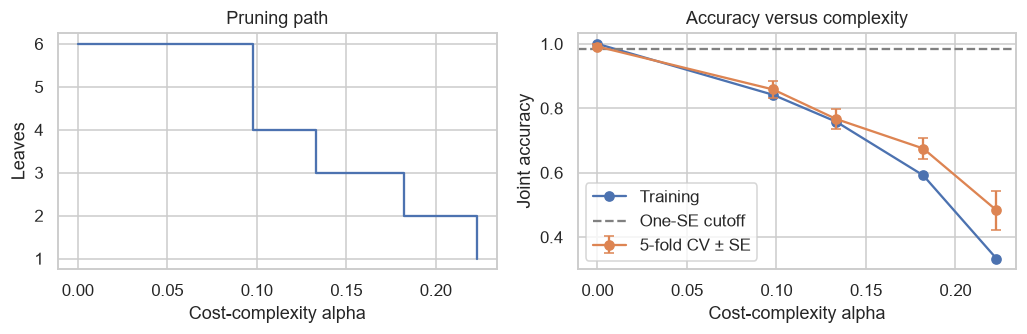

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2))
axes[0].step(pruning_results.ccp_alpha, pruning_results.leaves, where="post")
axes[0].set(xlabel="Cost-complexity alpha", ylabel="Leaves", title="Pruning path")
axes[1].plot(pruning_results.ccp_alpha, pruning_results.train_accuracy, "o-", label="Training")
axes[1].errorbar(pruning_results.ccp_alpha, pruning_results.cv_accuracy,
                 yerr=pruning_results.cv_se, fmt="o-", capsize=3, label="5-fold CV ± SE")
axes[1].axhline(accuracy_cutoff, color="gray", linestyle="--", label="One-SE cutoff")
axes[1].set(xlabel="Cost-complexity alpha", ylabel="Joint accuracy", title="Accuracy versus complexity")
axes[1].legend()
fig.tight_layout()
plt.show()

One-SE selection: alpha=0.000000, 6 leaves.


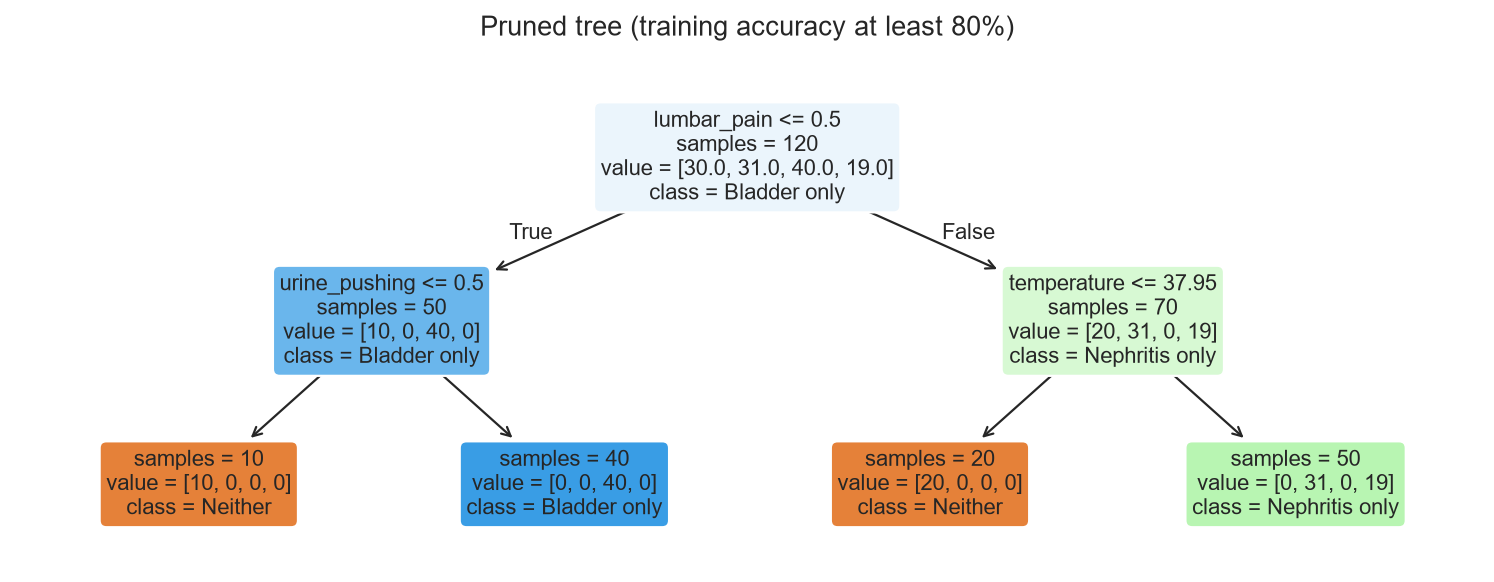

Rule 1: IF lumbar_pain = no AND urine_pushing = no
  THEN bladder inflammation = no; nephritis = no (n=10, purity=100.0%).
Rule 2: IF lumbar_pain = no AND urine_pushing = yes
  THEN bladder inflammation = yes; nephritis = no (n=40, purity=100.0%).
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 C
  THEN bladder inflammation = no; nephritis = no (n=20, purity=100.0%).
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 C
  THEN bladder inflammation = no; nephritis = yes (n=50, purity=62.0%).


In [8]:
print(f"One-SE selection: alpha={selected_tree.ccp_alpha:.6f}, "
      f"{selected_tree.get_n_leaves()} leaves.")
show_diagnosis_tree(simple_tree, "Pruned tree (training accuracy at least 80%)")
simple_rules = print_rules(simple_tree)

The one-standard-error rule keeps the original six-leaf tree, with mean CV
accuracy of 99.17%. The simpler tree has four leaves and depth two at
$\alpha=0.098167$. Its training accuracy is 84.17% and its mean CV accuracy is
85.83%.

The four-leaf tree gives shorter rules, but it never predicts both diseases
together. I would keep the six-leaf tree for prediction because pruning loses
too much accuracy. The four-leaf tree is the smallest subtree on this pruning
path that meets the chosen 80% training-accuracy cutoff.

## 2. The LASSO and Boosting for Regression

### (a) Obtain data

I used the first 1,495 rows for training and the remaining 499 for testing.
The response is `ViolentCrimesPerPop`. Based on `communities.names`, I dropped
`state`, `county`, `community`, `communityname`, and `fold`, leaving 122 predictors.

In [9]:
attribute_lines = (DATA_DIR / "communities.names").read_text(encoding="utf-8").splitlines()
community_columns = [line.split()[1] for line in attribute_lines
                     if line.lower().startswith("@attribute ")]
communities = pd.read_csv(DATA_DIR / "communities.data", header=None,
                          names=community_columns, na_values="?")
nonpredictive = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"
X = communities.drop(columns=nonpredictive + [target]).astype(float)
y = communities[target].astype(float)
X_train, X_test = X.iloc[:1495].copy(), X.iloc[1495:].copy()
y_train, y_test = y.iloc[:1495].copy(), y.iloc[1495:].copy()
display(pd.DataFrame({
    "partition": ["Training", "Test"], "rows": [len(X_train), len(X_test)],
    "predictors": [X_train.shape[1], X_test.shape[1]],
    "original rows (1-based)": ["1-1495", "1496-1994"],
}))

,partition,rows,predictors,original rows (1-based)
0,Training,1495,122,1-1495
1,Test,499,122,1496-1994


### (b) Missing values

I replaced missing values with each feature's training median because many of
the predictors are skewed. All 122 predictors are retained. The police variables
are missing for about 84% of the training observations, so their imputed values
should be interpreted cautiously.

The imputed data below are used for the plots. For cross-validation, imputation
is included in each model pipeline so the medians are fitted separately within
each training fold.

In [10]:
missing_summary = pd.DataFrame({
    "training_missing": X_train.isna().sum(),
    "training_missing_pct": 100 * X_train.isna().mean(),
    "test_missing": X_test.isna().sum(),
}).query("training_missing > 0 or test_missing > 0")
# Group features with the same missing-value counts.
display(missing_summary.groupby(["training_missing", "test_missing"])
        .size().rename("number_of_features").reset_index())
eda_imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(eda_imputer.fit_transform(X_train),
                               columns=X_train.columns, index=X_train.index)
X_test_imputed = pd.DataFrame(eda_imputer.transform(X_test),
                              columns=X_test.columns, index=X_test.index)
print(f"Missing predictor values before imputation: "
      f"train={int(X_train.isna().sum().sum()):,}, test={int(X_test.isna().sum().sum()):,}")
print("Remaining missing values:", X_train_imputed.isna().sum().sum(), "in training,",
      X_test_imputed.isna().sum().sum(), "in testing")

,training_missing,test_missing,number_of_features
0,1,0,1
1,1256,419,22


Missing predictor values before imputation: train=27,633, test=9,218
Remaining missing values: 0 in training, 0 in testing


### (c) Correlation matrix

The heatmap includes all 122 imputed training predictors in their original
column order. Every sixth axis label is shown to keep the figure readable.

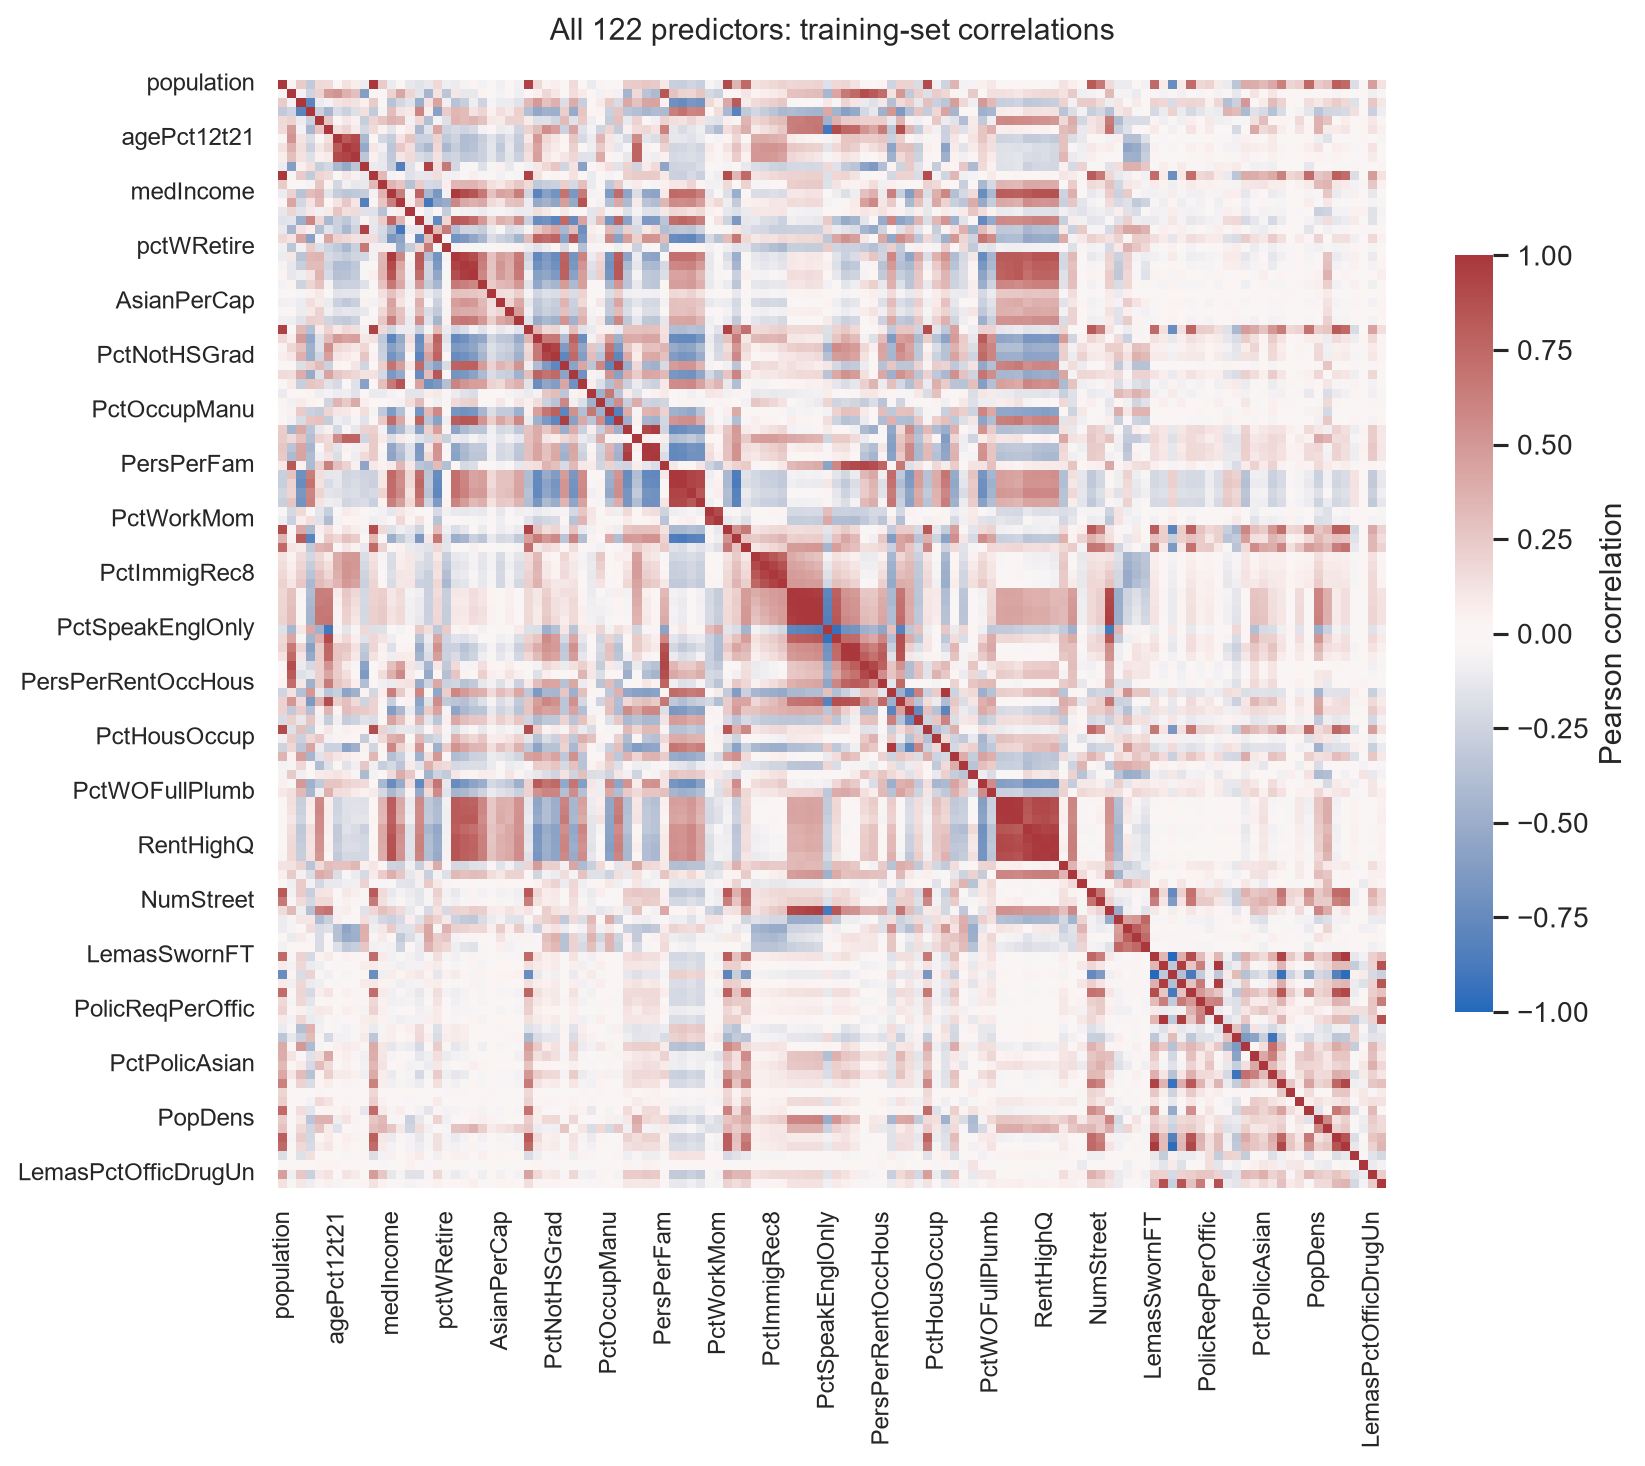

In [11]:
feature_correlation = X_train_imputed.corr()
fig, ax = plt.subplots(figsize=(9.5, 8.5), dpi=180)
sns.heatmap(feature_correlation, cmap="vlag", center=0, vmin=-1, vmax=1,
            xticklabels=6, yticklabels=6, square=True,
            cbar_kws={"label": "Pearson correlation", "shrink": 0.6}, ax=ax)
ax.tick_params(axis="both", labelsize=9.5)
ax.set_title("All 122 predictors: training-set correlations", pad=16)
fig.tight_layout()
plt.show()

Several groups are strongly correlated. For example, `population` and
`numbUrban` have a correlation of about 0.994, and the housing-value variables
are also highly correlated. This suggests substantial multicollinearity,
which motivates trying ridge regression and PCR.

### (d) Coefficient of variation

I calculated $CV=s/\bar{x}$ for each predictor using the imputed training data.
`ddof=1` gives the sample standard deviation. These CVs describe relative
variation on the dataset's normalized scale; they do not measure a feature's
relationship with the response.

In [12]:
cv_table = pd.DataFrame({
    "mean": X_train_imputed.mean(),
    "sample_std": X_train_imputed.std(ddof=1),
})
cv_table["CV"] = cv_table["sample_std"].div(cv_table["mean"].replace(0, np.nan))
cv_table = cv_table.sort_values("CV", ascending=False)
# Show every CV in three parallel lists instead of a 122-row table.
cv_values = cv_table[["CV"]].round(5).rename_axis("Feature").reset_index()
block_size = int(np.ceil(len(cv_values) / 3))
blocks = [cv_values.iloc[start:start + block_size].reset_index(drop=True)
          for start in range(0, len(cv_values), block_size)]
cv_compact = pd.concat(blocks, axis=1).fillna("")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(cv_compact)

,Feature,CV,Feature,CV,Feature,CV
0,PctPolicAsian,5.52706,PctLargHouseFam,0.73869,agePct12t21,0.36908
1,NumStreet,4.29292,pctWPubAsst,0.70621,PersPerOccupHous,0.36725
2,NumInShelters,3.47095,pctWFarmSelf,0.70190,pctWInvInc,0.36533
3,NumIlleg,3.05896,PctImmigRecent,0.68149,pctWSocSec,0.36072
4,NumImmig,2.92664,PctLess9thGrade,0.68049,FemalePctDiv,0.36039
5,LemasPctOfficDrugUn,2.55295,OtherPerCap,0.67328,householdsize,0.3558
6,NumUnderPov,2.34244,pctUrban,0.64332,PctEmploy,0.35145
7,LemasSwornFT,2.24804,RentLowQ,0.63966,PctPersOwnOccup,0.34921
8,population,2.24110,AsianPerCap,0.61487,pctWRetire,0.34542
9,numbUrban,2.03846,blackPerCap,0.59934,PolicPerPop,0.34427


### (e) Scatter plots and box plots

The assignment asks for $\lfloor\sqrt{128}\rfloor=11$ features. I selected the
11 highest CVs, plotted them against the response, and used box plots to compare
their distributions. The regression models below still use all 122 predictors.

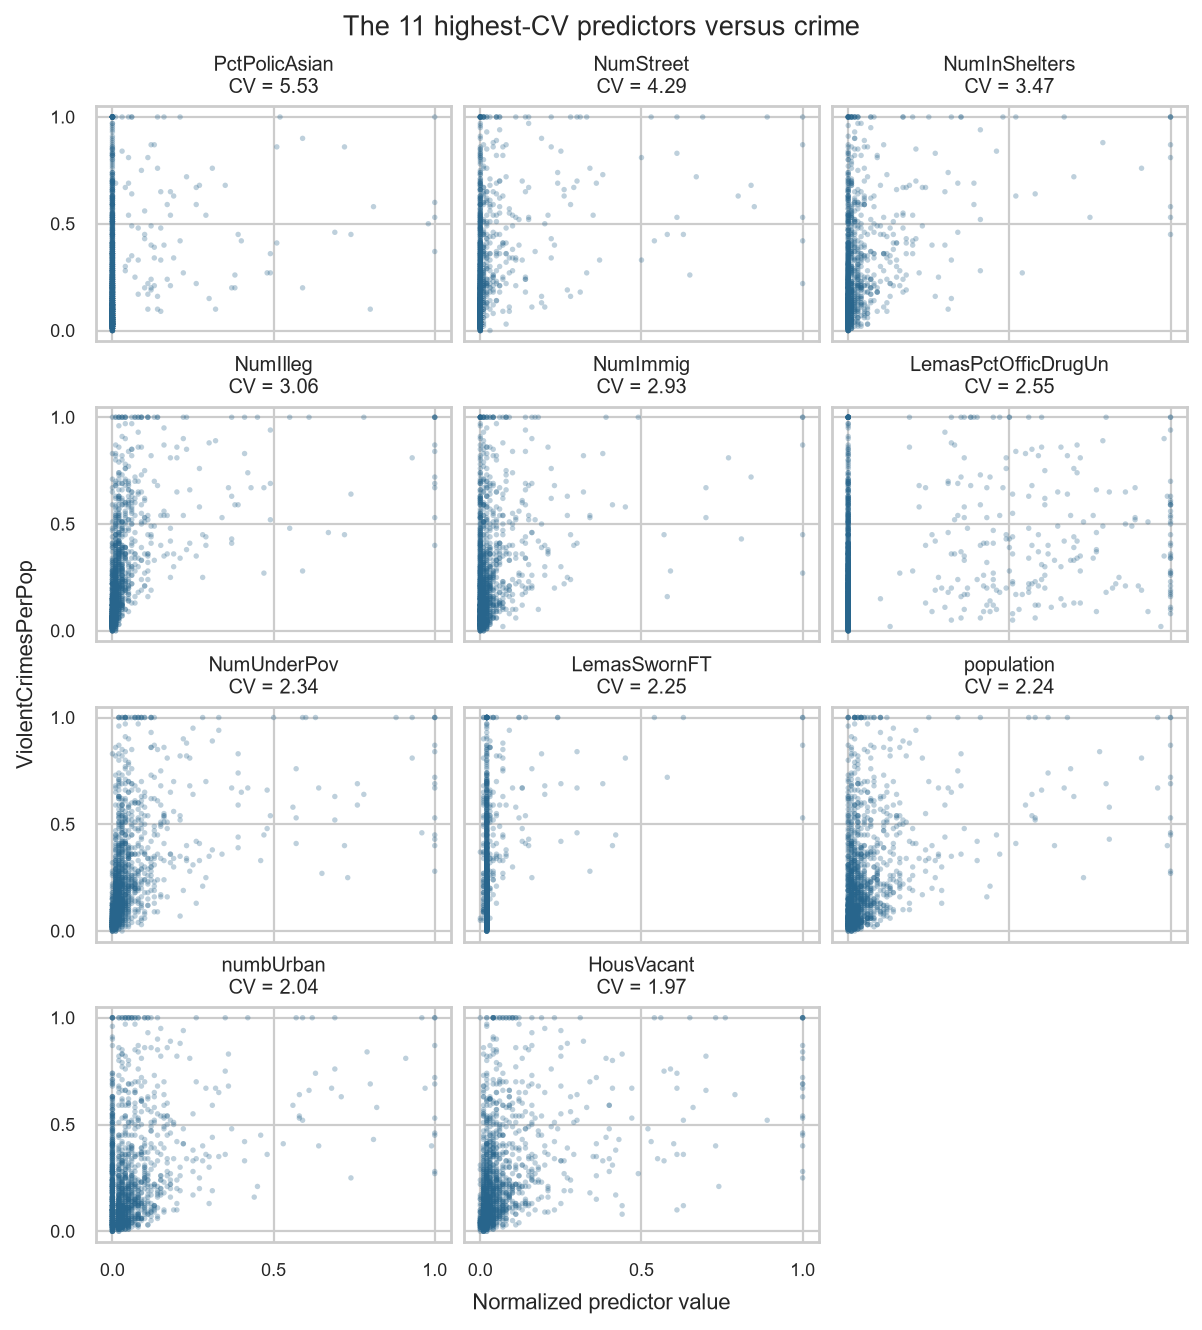

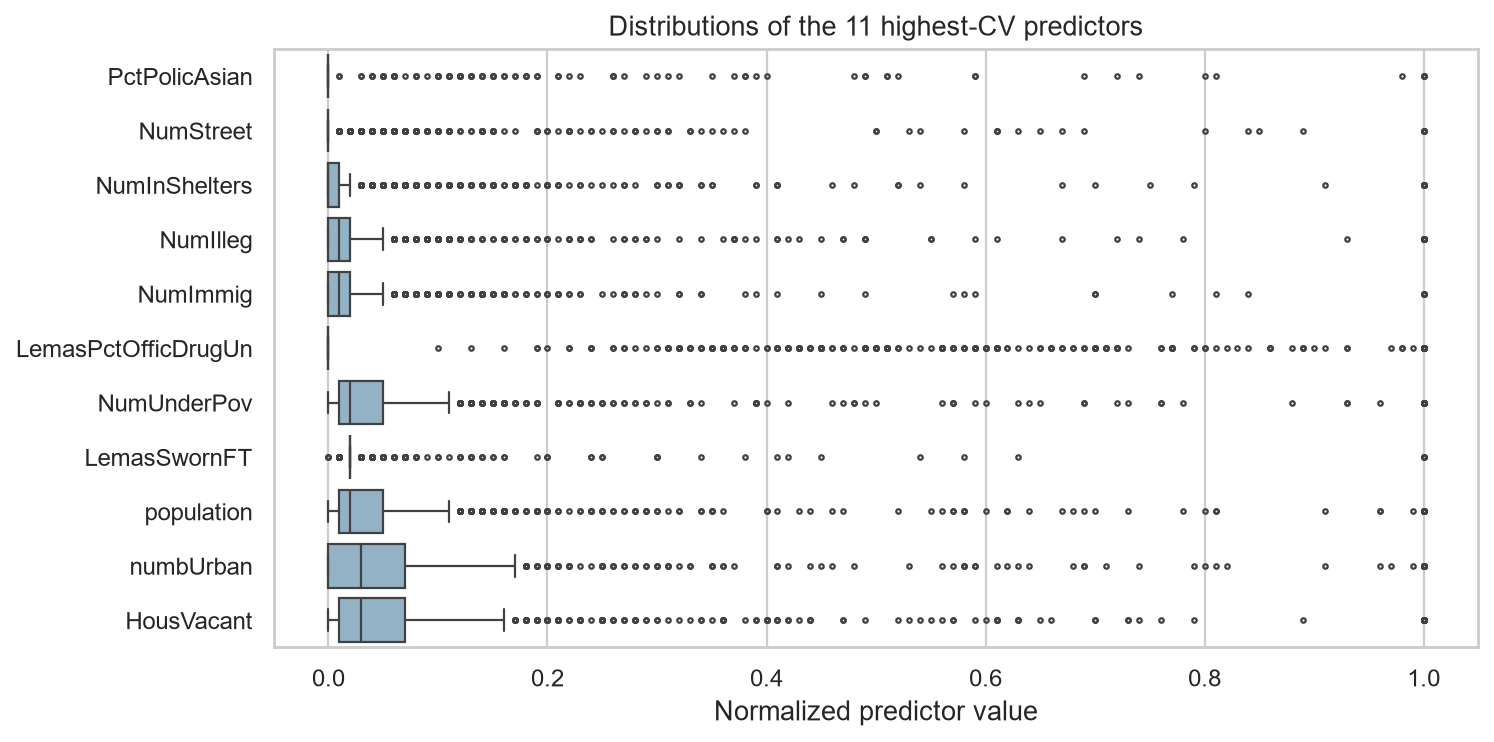

In [13]:
n_top = int(np.floor(np.sqrt(128)))
top_features = cv_table.head(n_top).index.tolist()

fig, axes = plt.subplots(4, 3, figsize=(7.4, 8.2), dpi=160,
                         sharex=True, sharey=True, layout="constrained")
for ax, feature in zip(axes.flat, top_features):
    ax.scatter(X_train_imputed[feature], y_train, s=6, alpha=0.3,
               color="#28658c", edgecolors="none")
    ax.set_title(f"{feature}\nCV = {cv_table.loc[feature, 'CV']:.2f}", fontsize=9)
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    ax.tick_params(labelsize=8)
for ax in axes.flat[len(top_features):]:
    ax.set_visible(False)
fig.supxlabel("Normalized predictor value", fontsize=10)
fig.supylabel("ViolentCrimesPerPop", fontsize=10)
fig.suptitle("The 11 highest-CV predictors versus crime", fontsize=12)
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 4.8), dpi=160)
sns.boxplot(data=X_train_imputed[top_features], orient="h", color="#8cb4ce",
            fliersize=2, linewidth=1, ax=ax)
ax.set(xlabel="Normalized predictor value", ylabel="",
       title="Distributions of the 11 highest-CV predictors")
fig.tight_layout()
plt.show()

Most of these features have small means and long right tails. `PctPolicAsian`
has the highest CV (5.53), but its median imputation also creates a large group
of zeros. Features such as `NumUnderPov` and `population` show some positive
association with crime, with considerable scatter.

The plots alone are not enough to conclude that a feature is statistically
significant. They only show marginal relationships and do not account for
correlation with other predictors or sampling uncertainty. A high CV can simply
result from dividing by a small mean.

### (f) Least-squares regression

I fitted an intercept and all 122 predictors. Test error is
$\mathrm{MSE}=\frac{1}{499}\sum_i(y_i-\hat{y}_i)^2$; I also report RMSE and $R^2$.
The training mean of the response serves as a baseline.

For this and the remaining models, I use the same shuffled 5-fold split of the
training set. Tuning uses validation MSE, and the test set is only used to
evaluate the fitted models. Scaling and PCA, where needed, are fitted inside
each fold along with imputation.

The selected parameters and errors for all six models are reported together
in the model comparison table at the end.

In [14]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train))
results = []

# Use the same scoring and folds for each grid search.
def fit_cv(pipeline, param_grid):
    search = GridSearchCV(
        pipeline, param_grid, cv=cv_splits,
        scoring="neg_mean_squared_error", n_jobs=1, error_score="raise"
    )
    with threadpool_limits(limits=1):
        search.fit(X_train, y_train)
    return search


def evaluate_model(name, model, cv_mse, parameter="None"):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, test_pred)
    row = {
        "Model": name,
        "Selected parameter": parameter,
        "CV MSE": cv_mse,
        "Training MSE": mean_squared_error(y_train, train_pred),
        "Test MSE": mse,
        "Test RMSE": np.sqrt(mse),
        "Test R2": r2_score(y_test, test_pred),
    }
    results.append(row)

In [15]:
baseline_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print(f"Training-mean baseline test MSE: {baseline_mse:.6f}")

ols = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression()),
])
with threadpool_limits(limits=1):
    ols_cv_mse = -cross_val_score(
        ols, X_train, y_train, cv=cv_splits, scoring="neg_mean_squared_error"
    ).mean()
    ols.fit(X_train, y_train)

evaluate_model("Least squares", ols, ols_cv_mse)

Training-mean baseline test MSE: 0.047666


Least squares gives a test MSE of 0.017966, compared with 0.047666 for the
training-mean baseline. The predictors improve substantially over simply
predicting the same crime rate for every community.

### (g) Ridge regression

I standardized the predictors and searched 49 values of $\lambda$ from $10^{-4}$
to $10^4$. Ridge shrinks the coefficients by minimizing
$\mathrm{RSS}+\lambda\sum_j\beta_j^2$. In scikit-learn, this penalty is `alpha`.

In [16]:
ridge = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge()),
])
ridge_search = fit_cv(ridge, {"model__alpha": np.logspace(-4, 4, 49)})
ridge_alpha = ridge_search.best_params_["model__alpha"]

evaluate_model("Ridge (standardized)", ridge_search.best_estimator_,
               -ridge_search.best_score_, f"lambda={ridge_alpha:.6g}")

CV selects $\lambda=68.1292$. The test MSE is 0.017450, slightly lower than
least squares. Shrinking the coefficients appears to help with the strong
correlations among predictors.

### (h) LASSO with and without standardization

I fitted LASSO on both the original features and standardized features, using
41 values of $\lambda$ from $10^{-5}$ to $10^{-1}$. The objective is
$\mathrm{RSS}/(2n)+\lambda\sum_j|\beta_j|$, which can set coefficients to zero.

The original features are already normalized to $[0,1]$, but their variances
still differ. Standardizing changes how the penalty is applied across features.
The selected variables below have coefficients with magnitude greater than
$10^{-8}$.

In [17]:
lasso_grid = {"model__alpha": np.logspace(-5, -1, 41)}

lasso_raw = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", Lasso(max_iter=100000, tol=1e-6)),
])
lasso_std = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=100000, tol=1e-6)),
])

lasso_raw_search = fit_cv(lasso_raw, lasso_grid)
lasso_std_search = fit_cv(lasso_std, lasso_grid)
lasso_raw_alpha = lasso_raw_search.best_params_["model__alpha"]
lasso_std_alpha = lasso_std_search.best_params_["model__alpha"]

evaluate_model("LASSO (original scale)", lasso_raw_search.best_estimator_,
               -lasso_raw_search.best_score_, f"lambda={lasso_raw_alpha:.6g}")
evaluate_model("LASSO (standardized)", lasso_std_search.best_estimator_,
               -lasso_std_search.best_score_, f"lambda={lasso_std_alpha:.6g}")

In [18]:
# Nonzero coefficients identify the selected variables in each fit.
raw_coefs = pd.Series(lasso_raw_search.best_estimator_.named_steps["model"].coef_,
                      index=X_train.columns)
std_coefs = pd.Series(lasso_std_search.best_estimator_.named_steps["model"].coef_,
                      index=X_train.columns)
raw_selected = raw_coefs[raw_coefs.abs() > 1e-8].sort_values(key=abs, ascending=False)
std_selected = std_coefs[std_coefs.abs() > 1e-8].sort_values(key=abs, ascending=False)



# Report the full variable lists; coefficient magnitudes are not requested.
for label, selected in [("Original scale", raw_selected), ("Standardized", std_selected)]:
    print(f"{label}: {len(selected)} selected variables")
    print(fill(", ".join(selected.index), width=95, break_long_words=False))
    print()


Original scale: 75 selected variables
agePct12t29, racepctblack, PctPersDenseHous, PctKids2Par, MedRent, RentLowQ, NumStreet,
PctEmploy, MalePctNevMarr, PctPopUnderPov, PctWorkMom, MalePctDivorce, HousVacant, pctWInvInc,
pctWRetire, NumImmig, NumIlleg, FemalePctDiv, PctIlleg, PolicReqPerOffic, pctWWage,
MedRentPctHousInc, PctLargHouseOccup, PctNotSpeakEnglWell, MedOwnCostPctIncNoMtg,
LemasSwFTFieldPerPop, agePct12t21, PctVacantBoarded, PersPerOccupHous, NumInShelters,
PctHousLess3BR, PctPersOwnOccup, whitePerCap, PctVacMore6Mos, pctWSocSec, PctHousOccup,
PctForeignBorn, PctUsePubTrans, pctWPubAsst, pctUrban, PctRecImmig10, LemasGangUnitDeploy,
PctYoungKids2Par, LandArea, NumKindsDrugsSeiz, indianPerCap, PolicCars, pctWFarmSelf,
AsianPerCap, PctHousNoPhone, PctWOFullPlumb, RacialMatchCommPol, HispPerCap, PctSameCity85,
OtherPerCap, PctPolicAsian, PctPolicHisp, blackPerCap, PctLess9thGrade, OwnOccLowQuart,
PctPolicBlack, PctEmplManu, MedOwnCostPctInc, racePctAsian, PctOccupManu, LemasPct

Without standardization, CV selects lambda = 0.0001 and LASSO retains
75 variables. Its test MSE is 0.017658. With standardization, lambda =
0.000630957, 76 variables are retained, and test MSE is 0.017722.

The original-scale model performs slightly better on this test set, although
the difference is small. Standardization changes the relative penalties and
the selected variables; it does not guarantee lower test error. A nonzero
LASSO coefficient should not be interpreted as a significance test.

### (i) Principal component regression

I standardized the predictors, applied PCA, and regressed the response on the
first $M$ components. I searched all $M=1,\ldots,122$ using CV MSE. PCA maximizes
predictor variance without using the response, so retaining more variance does
not necessarily give better predictions.

In [19]:
pcr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("model", LinearRegression()),
])
pcr_search = fit_cv(pcr, {"pca__n_components": list(range(1, X_train.shape[1] + 1))})
best_m = int(pcr_search.best_params_["pca__n_components"])
evaluate_model("PCR (standardized)", pcr_search.best_estimator_,
                            -pcr_search.best_score_, f"M={best_m}")
retained_variance = pcr_search.best_estimator_.named_steps["pca"].explained_variance_ratio_.sum()
print(f"Variance explained by the selected components: {retained_variance:.2%}")

Variance explained by the selected components: 99.80%


CV selects $M=93$, which explains 99.80% of the standardized predictor
variance. The test MSE is 0.018264. PCR reduces the number of inputs, but
it performs slightly worse than least squares and the regularized linear
models on this test set.

### (j) L1-regularized gradient boosting

I used XGBoost with 400 trees, depth 3, and learning rate 0.03. I kept these
settings fixed and tuned `reg_alpha` using 5-fold CV over zero and 17 positive
values from $10^{-4}$ to $10^2$. The L2 penalty `reg_lambda` is fixed at 1.

For the tree booster, `reg_alpha` penalizes the absolute leaf weights. This is
the L1-regularized tree implementation suggested in the assignment, though it
does not fit a separate LASSO regression at each node.

In [20]:
xgb_alpha_grid = np.r_[0.0, np.logspace(-4, 2, 17)]
xgb_model = XGBRegressor(
    objective="reg:squarederror", booster="gbtree", tree_method="hist",
    n_estimators=400, learning_rate=0.03, max_depth=3,
    min_child_weight=1, subsample=1.0, colsample_bytree=1.0,
    reg_lambda=1.0, random_state=SEED, n_jobs=1, verbosity=0,
)
xgb = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", xgb_model),
])
xgb_search = fit_cv(xgb, {"model__reg_alpha": xgb_alpha_grid})
xgb_alpha = float(xgb_search.best_params_["model__reg_alpha"])
evaluate_model("XGBoost (L1)", xgb_search.best_estimator_,
                           -xgb_search.best_score_, f"alpha={xgb_alpha:.6g}")

The selected L1 penalty is $\alpha=1.333521$. The test MSE is 0.016157,
the lowest among the models fitted here. The training MSE is much lower
(0.009361), so there is still a noticeable gap between training and test performance.

### Model comparison

The following table compares all six models on the same training and test sets.
The selected hyperparameters come from training-set cross-validation.

In [21]:
comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(6))

,Selected parameter,CV MSE,Training MSE,Test MSE,Test RMSE,Test R2
Model,,,,,,
Least squares,None,0.020110,0.016292,0.017966,0.134038,0.622204
Ridge (standardized),lambda=68.1292,0.019140,0.016939,0.017450,0.132100,0.633050
LASSO (original scale),lambda=0.0001,0.018991,0.016861,0.017658,0.132883,0.628689
LASSO (standardized),lambda=0.000630957,0.019103,0.016903,0.017722,0.133123,0.627344
PCR (standardized),M=93,0.019449,0.016724,0.018264,0.135145,0.615937
XGBoost (L1),alpha=1.33352,0.019673,0.009361,0.016157,0.127109,0.660255


XGBoost has the lowest test MSE, while original-scale LASSO has the lowest
CV MSE (0.018991). These rankings differ, so I would not conclude that
XGBoost will always outperform LASSO from this one test split. Ridge improves
slightly on least squares, and PCR has the highest test error of the six models.

All models beat the training-mean baseline. One limitation is the amount of
missing police data: median imputation lets us use these columns, but it
cannot recover the information that was not observed.